# STAC data prep - Global Sedimentary Thickness model 1 (GST-1), XYZ to COG

Notebook to migrate GST-1 (Bird & Mooney) from a text XYZ file to one **Cloud Optimized GeoTIFF (CoG)**, published in GeoServer WMS.

- **Case:** `GST1_WGS84.XYZ`, a text table with the columns `lat`, `Lon`, `meter` (sediment thickness in m). The points form a complete regular grid of 0.125 degree (2881 x 1441 points, about 4.15 million rows), so the data is a **2D raster, one variable, one layer**.
- **Format:** one COG (see `DATA_FORMATS.md`: 2D raster, single layer). It is only about 4 million cells, so a single file with overviews is enough; no Zarr or tiling is needed.
- **Grid convention:** each XYZ point is the **centre** of a 0.125 degree cell, so the raster starts half a cell outside the globe (`-180.0625, 90.0625`). Cell values are not moved or resampled.
- **Values:** `float32`, metres, nodata `-9999` (the XYZ file has no gaps; the nodata value is only used for cells that would be missing).
- **Overviews:** `AVERAGE` (continuous quantity).
- **Metadata template:** `metadata/metadata_GST.json`. The empty fields are filled below.

Source: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\GST1_WGS84.XYZ`.

**Running in docker:** the `P:` drive is not visible in the container, so run from the host:

```powershell
docker\run_notebook_with_p_drive.ps1 -Notebook 31_gst.ipynb -Variable gst -InputPattern "GST1_WGS84.XYZ"
```

### Import packages

In [1]:
import json
import os
import shutil
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.shutil import copy as rio_copy
from rasterio.transform import from_origin

### Define drive paths

`DATA_VIVIAN` and `STAC_DATA_REPO` are set in the docker container; otherwise the Windows host paths are used.

In [2]:
COLLECTION_ID = "gst"
ITEM_ID = "gst"
RES = 0.125  # degrees
NODATA = -9999.0
UNITS = "m"
# GST-1 is a static model without an observation period; the publication year is used as the validity date
TEMPORAL_EXTENT = ["2026-01-01T00:00:00Z", "2026-12-31T23:59:59Z"]

data_vivian = Path(os.environ.get("DATA_VIVIAN", r"P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian"))
stac_repo = Path(os.environ.get("STAC_DATA_REPO", r"C:\Ocean\Work\Projects\2025\STAC\Tools\Repositories\global-coastal-atlas\STAC\data"))

source_xyz = data_vivian / "GST1_WGS84.XYZ"
metadata_template_path = stac_repo / "metadata" / "metadata_GST.json"

processed_data_dir = data_vivian / "stac" / COLLECTION_ID
cog_dir = processed_data_dir / "cog"
cog_dir.mkdir(parents=True, exist_ok=True)
cog_path = cog_dir / f"{ITEM_ID}.tif"

for p in (source_xyz, metadata_template_path):
    if not p.is_file():
        raise FileNotFoundError(p)
print("Source:", source_xyz)
print("Metadata template:", metadata_template_path)
print("Output COG:", cog_path)

Source: P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\GST1_WGS84.XYZ
Metadata template: C:\Ocean\Work\Projects\2025\STAC\Tools\Repositories\global-coastal-atlas\STAC\data\metadata\metadata_GST.json
Output COG: P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\gst\cog\gst.tif


### Read raw data

Whitespace separated text with a header line (`lat Lon meter`). About 4.15 million rows, it fits in memory.

In [3]:
xyz = pd.read_csv(source_xyz, sep=r"\s+", dtype={"lat": "float64", "Lon": "float64", "meter": "float32"})
print(xyz.shape, list(xyz.columns))
display(xyz.head())
print(xyz.describe().T[["min", "max", "mean"]])
print("NaN values:", int(xyz["meter"].isna().sum()))

(4151521, 3) ['lat', 'Lon', 'meter']


,lat,Lon,meter
0,-90.0,-180.000,1356.800049
1,-90.0,-179.875,1356.800049
2,-90.0,-179.750,1356.800049
3,-90.0,-179.625,1356.800049
4,-90.0,-179.500,1356.800049


         min      max         mean
lat    -90.0     90.0     0.000000
Lon   -180.0    180.0     0.000000
meter    0.0  20118.0  1260.983521
NaN values: 0


### Check that the points form a regular grid

The conversion to a raster only makes sense when every point lies on a 0.125 degree grid and no cell is filled twice.

In [4]:
lat0, lat1 = xyz["lat"].min(), xyz["lat"].max()
lon0, lon1 = xyz["Lon"].min(), xyz["Lon"].max()
nrow = int(round((lat1 - lat0) / RES)) + 1
ncol = int(round((lon1 - lon0) / RES)) + 1
print(f"lat {lat0} .. {lat1} | lon {lon0} .. {lon1} | grid {ncol} x {nrow} = {ncol * nrow:,} cells | rows in file {len(xyz):,}")

# row 0 is the northernmost latitude, column 0 the westernmost longitude
rows_f = (lat1 - xyz["lat"].to_numpy()) / RES
cols_f = (xyz["Lon"].to_numpy() - lon0) / RES
rows, cols = np.rint(rows_f).astype(int), np.rint(cols_f).astype(int)

assert np.abs(rows_f - rows).max() < 1e-6, "Latitudes are not on a regular grid"
assert np.abs(cols_f - cols).max() < 1e-6, "Longitudes are not on a regular grid"
assert rows.min() == 0 and rows.max() == nrow - 1 and cols.min() == 0 and cols.max() == ncol - 1
cell_id = rows.astype(np.int64) * ncol + cols
assert np.unique(cell_id).size == len(xyz), "Some grid cells are filled more than once"
print(f"OK: regular grid, {len(xyz) / (ncol * nrow):.1%} of the cells are filled")

lat -90.0 .. 90.0 | lon -180.0 .. 180.0 | grid 2881 x 1441 = 4,151,521 cells | rows in file 4,151,521
OK: regular grid, 100.0% of the cells are filled


### Check CF compliancy original file

Not applicable for a text XYZ file. The CRS (EPSG:4326, the file name says WGS84), nodata, units and attributes are written explicitly in the metadata file.

### Make CF compliant alterations (dataset dependent)

- Place the values on the grid; each point is the centre of its cell, so the raster origin is half a cell outside the globe.
- Keep the values unchanged (`float32`, metres).
- Fill the metadata fields that are empty in the template: `COLLECTION_ID`, `SPATIAL_EXTENT`, `SPATIAL_RESOLUTION`, `NODATA`, `DATA_TYPE`, `DIMENSIONS`, `MEDIA_TYPE`, `DATA_MODEL`, `UNITS`, `TEMPORAL_EXTENT`, ...
- `ITEMS` holds the item title and description for the STAC builder.

valid cells 4,151,521 of 4,151,521 | min 0.0 m | mean 1261.0 m | max 20118.0 m


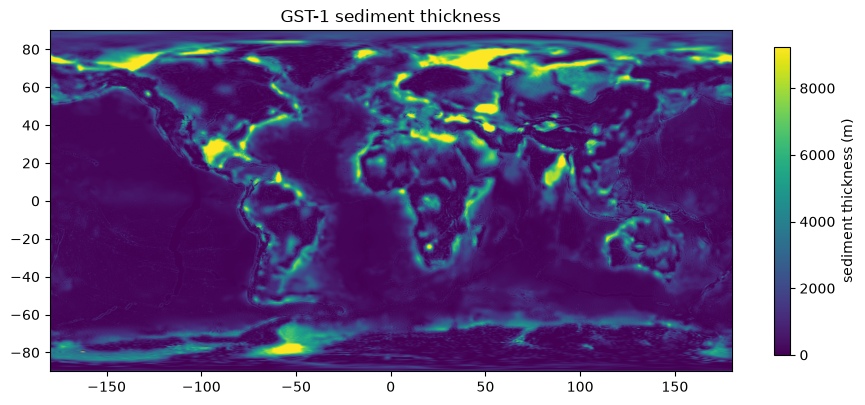

SPATIAL_EXTENT: [-180.0, -90.0, 180.0, 90.0] | RES: 0.125 | NODATA: -9999.0


In [5]:
grid = np.full((nrow, ncol), NODATA, dtype="float32")
grid[rows, cols] = xyz["meter"].to_numpy(dtype="float32")
grid[~np.isfinite(grid)] = NODATA

transform = from_origin(lon0 - RES / 2, lat1 + RES / 2, RES, RES)
profile = dict(driver="GTiff", height=nrow, width=ncol, count=1, dtype="float32", crs="EPSG:4326",
               transform=transform, nodata=NODATA)

valid = grid[grid != NODATA]
print(f"valid cells {valid.size:,} of {grid.size:,} | min {valid.min():.1f} m | mean {valid.mean():.1f} m | max {valid.max():.1f} m")

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(np.ma.masked_equal(grid, NODATA), extent=(lon0, lon1, lat0, lat1), cmap="viridis", vmin=0, vmax=np.percentile(valid, 99))
fig.colorbar(im, label="sediment thickness (m)", shrink=0.8)
ax.set_title("GST-1 sediment thickness")
plt.show()

with open(metadata_template_path, encoding="utf-8") as f:
    metadata = json.load(f)

bbox = [-180.0, -90.0, 180.0, 90.0]  # the half cell outside the globe is cut off for the STAC extent

metadata.update({
    "TITLE_ABBREVIATION": "GST1",
    "SHORT_DESCRIPTION": "GST-1 global sedimentary thickness model in m, 0.125 degree grid.",
    "INSTITUTION": "Bird Geophysical",
    "HISTORY": [
        "GST-1 (Bird & Mooney), a global sediment thickness model derived from 3D free-air gravity inversions that modify Mooney et al. (2023)",
        "Delivered as an XYZ text file (lat, Lon, meter); converted to a Cloud Optimized GeoTIFF (DEFLATE with floating point predictor, average overviews); values unchanged",
    ],
    "MEDIA_TYPE": "image/tiff; application=geotiff; profile=cloud-optimized",
    "DATA_MODEL": "raster_cog",
    "DIMENSIONS": ["x", "y"],
    "SPATIAL_EXTENT": bbox,
    "TEMPORAL_EXTENT": TEMPORAL_EXTENT,
    "KEYWORDS": ["sediment thickness", "sedimentary basins", "gravity inversion", "geology", "global"],
    "TAGS": ["geology", "sediment", "thickness", "cog"],
    "LONG_NAME": "Sediment thickness",
    "UNITS": UNITS,
    "COMMENT": (
        "Thickness of the sedimentary cover in m on a 0.125 degree grid. Each XYZ point is the centre of a cell. "
        f"{NODATA:.0f} is nodata. The model is static; the period in the temporal extent is the publication year."
    ),
    "CRS": "EPSG:4326",
    "ITEM_BBOX_CRS": "EPSG:4326",
    "SPATIAL_RESOLUTION": RES,
    "NODATA": NODATA,
    "DATA_TYPE": "float32",
    "COLLECTION_ID": COLLECTION_ID,
    "WMS_DATASET": COLLECTION_ID,  # GeoServer workspace used by scripts/31_gst.ipynb
    "ITEMS": {
        ITEM_ID: {
            "TITLE": "GST-1 sediment thickness (0.125 degree)",
            "DESCRIPTION": "Global sedimentary thickness model GST-1 in m on a 0.125 degree grid.",
        }
    },
})
metadata["PROVIDERS"]["name"] = metadata["PROVIDERS"]["name"].strip()
metadata["PROVIDERS"]["roles"] = metadata["PROVIDERS"].get("roles") or "producer"
metadata["TITLE"] = metadata["TITLE"].strip()
print("SPATIAL_EXTENT:", metadata["SPATIAL_EXTENT"], "| RES:", metadata["SPATIAL_RESOLUTION"], "| NODATA:", metadata["NODATA"])

### Write data to CoG

The grid is written to a plain GeoTIFF in a local temp folder, then GDAL's `COG` driver builds the tiled file with overviews. The result is copied to `P:`.

In [6]:
with tempfile.TemporaryDirectory(prefix="gst_cog_") as tmp:
    plain = Path(tmp) / "gst_plain.tif"
    with rasterio.open(plain, "w", **profile) as dst:
        dst.write(grid, 1)
        dst.update_tags(AREA_OR_POINT="Area")

    tmp_cog = Path(tmp) / cog_path.name
    rio_copy(
        plain, tmp_cog,
        driver="COG",
        COMPRESS="DEFLATE",
        PREDICTOR="3",  # floating point predictor
        BLOCKSIZE=512,
        OVERVIEW_RESAMPLING="AVERAGE",
        BIGTIFF="IF_SAFER",
    )
    print(f"COG built ({tmp_cog.stat().st_size / 1e6:.1f} MB)")
    shutil.copyfile(tmp_cog, cog_path)
print("Wrote COG:", cog_path, f"({cog_path.stat().st_size / 1e6:.1f} MB)")

metadata_output_path = processed_data_dir / f"metadata_{COLLECTION_ID}.json"
with open(metadata_output_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)
print("Wrote metadata:", metadata_output_path)

COG built (13.9 MB)
Wrote COG: P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\gst\cog\gst.tif (13.9 MB)
Wrote metadata: P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\gst\metadata_gst.json


### Verify the output

The COG is compared with the XYZ table for **every** point (the file is small enough), and the structure is checked.

In [7]:
with rasterio.open(cog_path) as dst:
    assert dst.dtypes[0] == "float32" and dst.nodata == NODATA
    assert dst.crs.to_epsg() == 4326
    assert dst.shape == (nrow, ncol) and dst.transform == transform
    assert dst.is_tiled, "COG must be internally tiled"
    assert len(dst.overviews(1)) > 0, "COG must have overviews"
    print(f"block {dst.profile.get('blockxsize')} x {dst.profile.get('blockysize')} | overviews {dst.overviews(1)} | compression {dst.compression}")
    arr = dst.read(1)
    # sample every point through the georeferencing (independent of the row/col arithmetic used above)
    r, c = rasterio.transform.rowcol(dst.transform, xyz["Lon"].to_numpy(), xyz["lat"].to_numpy())

sampled = arr[np.asarray(r), np.asarray(c)]
n_diff = int((sampled != xyz["meter"].to_numpy(dtype="float32")).sum())
print(f"points compared: {len(xyz):,} | different: {n_diff}")
assert n_diff == 0
print("OK: the GST-1 COG holds exactly the values of the XYZ file; metadata is ready for the STAC builder notebook.")

block 512 x 512 | overviews [2, 4, 8] | compression Compression.deflate
points compared: 4,151,521 | different: 0
OK: the GST-1 COG holds exactly the values of the XYZ file; metadata is ready for the STAC builder notebook.
